# Dyson Air Multiplier Hypothesis Test
Use this notebook to inspect data and prepare values for SocSciStatistics t-test.

In [11]:
# ── 0. Install / Import Libraries ─────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)   # reproducibility
print('Libraries loaded ✓')

Libraries loaded ✓


In [12]:
# ── 1. Generate Full Dataset ───────────────────────────────────────────────────
POPULATION_MEAN_H0 = 27.0        # claimed / null mean airflow (15x standard fan)
TRUE_MEAN          = 28.2        # actual population mean after testing
SIGMA              = 2.5         # known population std dev
N_FULL             = 200         # total dataset size

# Simulated Dyson Air Multiplier™ airflow readings
airflow = np.random.normal(loc=TRUE_MEAN, scale=SIGMA, size=N_FULL)
airflow = np.clip(airflow, 20, 35)   # keep readings in realistic range

df_full = pd.DataFrame({
    'unit_id':  np.arange(1, N_FULL + 1),
    'airflow':  np.round(airflow, 2)
})

print(f'Dataset shape : {df_full.shape}')
print(f'Sample mean   : {df_full.airflow.mean():.4f}')
print(f'Sample std    : {df_full.airflow.std():.4f}')
df_full.head(10)

Dataset shape : (200, 2)
Sample mean   : 28.0978
Sample std    : 2.3276


,unit_id,airflow
0,1,29.44
1,2,27.85
2,3,29.82
3,4,32.01
4,5,27.61
5,6,27.61
6,7,32.15
7,8,30.12
8,9,27.03
9,10,29.56


## Hypotheses
- H0: No signifacannt difference
- H1: Dyson airflow is approximately 15x standard fan airflow.

count    200.000000
mean      28.097850
std        2.327641
min       21.650000
25%       26.432500
50%       28.190000
75%       29.450000
max       35.000000


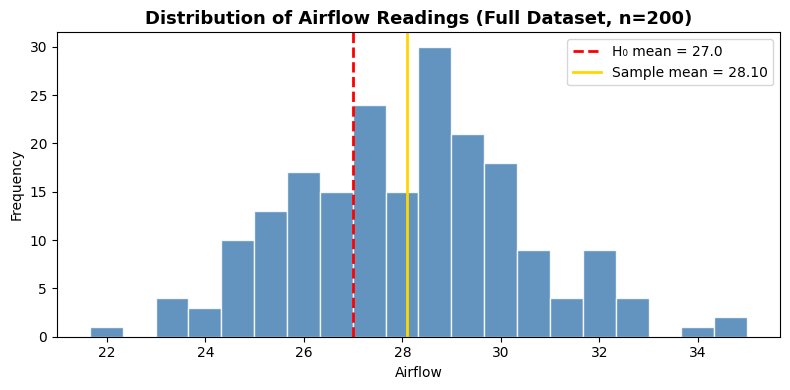

In [13]:
# ── 1b. Descriptive Statistics ─────────────────────────────────────────────────
desc = df_full['airflow'].describe().rename('Airflow Statistics')
print(desc.to_string())

# Histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_full['airflow'], bins=20, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(POPULATION_MEAN_H0, color='red',    lw=2, ls='--', label=f'H₀ mean = {POPULATION_MEAN_H0}')
ax.axvline(df_full.airflow.mean(), color='gold', lw=2, ls='-',  label=f'Sample mean = {df_full.airflow.mean():.2f}')
ax.set_title('Distribution of Airflow Readings (Full Dataset, n=200)', fontsize=13, fontweight='bold')
ax.set_xlabel('Airflow'); ax.set_ylabel('Frequency')
ax.legend(); plt.tight_layout(); plt.show()

In [14]:
# ── 2. Z-Test Loop ─────────────────────────────────────────────────────────────
sample_sizes = [4, 9, 16, 25, 36, 49, 64, 100]
ALPHA = 0.05

rows = []
for n in sample_sizes:
    sample  = df_full['airflow'].iloc[:n].values          # first n rows (fixed seed → reproducible)
    x_bar   = sample.mean()
    se      = SIGMA / np.sqrt(n)                        # Standard Error
    z_stat  = (x_bar - POPULATION_MEAN_H0) / se        # Z statistic
    p_val   = 2 * (1 - stats.norm.cdf(abs(z_stat)))    # two-tailed p-value

    decision      = 'Reject H₀'      if p_val < ALPHA else 'Do not reject H₀'
    reject        = p_val < ALPHA

    # Interpretation (mirrors the slide logic)
    if   p_val >= 0.50: interp = 'Difference likely due to randomness'
    elif p_val >= 0.30: interp = 'Weak evidence of change'
    elif p_val >= 0.20: interp = 'Still insufficient evidence'
    elif p_val >= 0.10: interp = 'Trending but not significant'
    elif p_val >= 0.05: interp = 'Very close to significance'
    elif p_val >= 0.02: interp = 'Statistically significant difference'
    elif p_val >= 0.01: interp = 'Strong evidence of difference'
    else:               interp = 'Very strong evidence'

    rows.append({
        'Sample Size (n)':           n,
        'Sample Mean':               round(x_bar, 4),
        'Standard Error (σ/√n)':     round(se, 2),
        'Z-Statistic':               round(z_stat, 2),
        'p-value (approx)':          round(p_val, 4),
        'Decision (α = 0.05)':       decision,
        'Interpretation':            interp,
        '_reject':                   reject      # helper column for styling
    })

df_z = pd.DataFrame(rows)
print('Z-Test results computed ✓')

Z-Test results computed ✓


In [15]:
# ── 3. Styled Table (mimicking the slide) ─────────────────────────────────────

DISPLAY_COLS = ['Sample Size (n)', 'Standard Error (σ/√n)', 'Z-Statistic',
                'p-value (approx)', 'Decision (α = 0.05)', 'Interpretation']

def highlight_rows(row):
    """Yellow for reject rows, light yellow for 'weak evidence' row."""
    styles = [''] * len(row)
    if row['_reject']:
        styles = ['background-color: #FFD700; font-weight: bold; color: #222'] * len(row)
    elif 'Weak evidence' in row['Interpretation']:
        styles = ['background-color: #FFF3A3; color: #333'] * len(row)
    return styles

styled = (
    df_z[DISPLAY_COLS + ['_reject']]
    .style
    .apply(highlight_rows, axis=1)
    .hide(axis='columns', subset=['_reject'])
    .set_caption('Final Result : Two-tailed test at Significance level α = 0.05')
    .set_properties(**{'text-align': 'center', 'border': '1px solid #ccc', 'padding': '6px 10px'})
    .set_table_styles([
        {'selector': 'caption',
         'props': 'font-size:14px; font-weight:bold; padding-bottom:8px;'},
        {'selector': 'th',
         'props': 'background-color:#2c3e50; color:white; text-align:center; padding:8px;'},
        {'selector': 'table',
         'props': 'border-collapse:collapse; width:100%;'}
    ])
)

styled

,Sample Size (n),Standard Error (σ/√n),Z-Statistic,p-value (approx),Decision (α = 0.05),Interpretation
0,4,1.250000,2.220000,0.026100,Reject H₀,Statistically significant difference
1,9,0.830000,2.750000,0.005900,Reject H₀,Very strong evidence
2,16,0.620000,1.820000,0.069100,Do not reject H₀,Very close to significance
3,25,0.500000,1.580000,0.113400,Do not reject H₀,Trending but not significant
4,36,0.420000,1.900000,0.056800,Do not reject H₀,Very close to significance
5,49,0.360000,2.000000,0.045200,Reject H₀,Statistically significant difference
6,64,0.310000,2.310000,0.020800,Reject H₀,Statistically significant difference
7,100,0.250000,3.760000,0.000200,Reject H₀,Very strong evidence


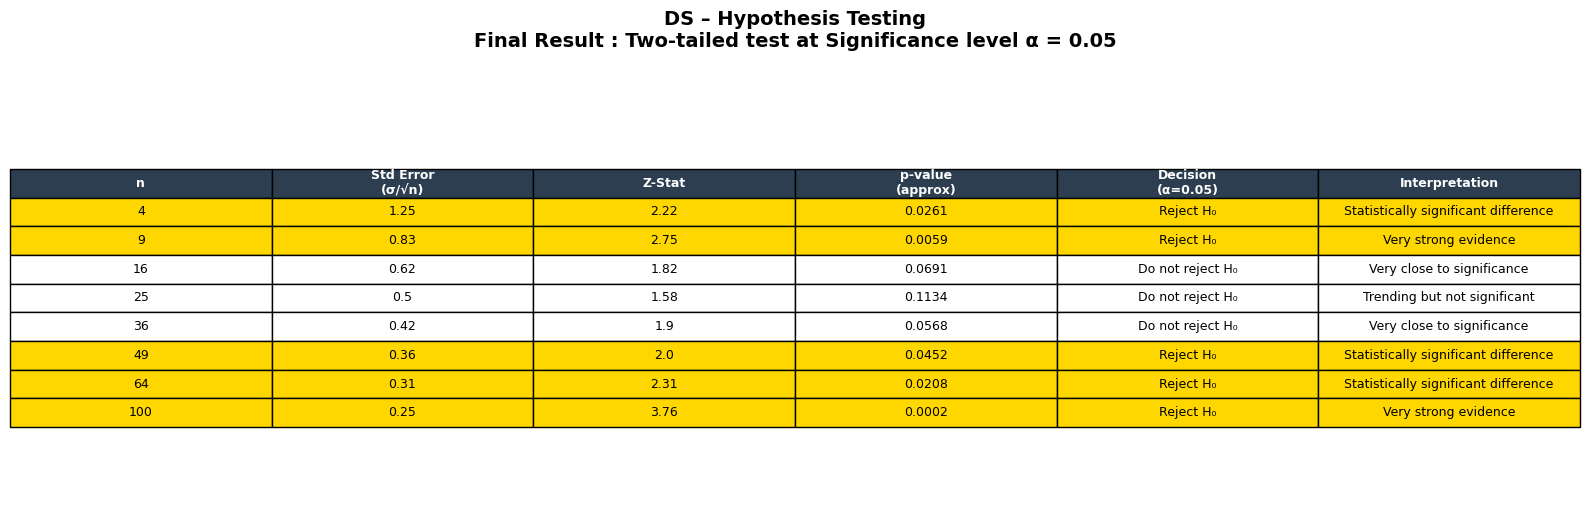

Table saved → c:\Users\siddi\OneDrive\Desktop\College\TE\SEM 6\Labs\DS Lab\dyson_hypothesis_table.png ✓


In [21]:
# ── 4. Matplotlib version of the table (for saving/presentations) ──────────────
import os

# ✅ Save to current working directory (works on any machine)
output_dir = os.getcwd()
save_path = os.path.join(output_dir, 'dyson_hypothesis_table.png')

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

# Title
fig.suptitle('DS – Hypothesis Testing\nFinal Result : Two-tailed test at Significance level α = 0.05',
             fontsize=14, fontweight='bold', y=1.02)

col_labels = ['n', 'Std Error\n(σ/√n)', 'Z-Stat', 'p-value\n(approx)',
              'Decision\n(α=0.05)', 'Interpretation']

table_data = [
    [r['Sample Size (n)'], r['Standard Error (σ/√n)'], r['Z-Statistic'],
     r['p-value (approx)'], r['Decision (α = 0.05)'], r['Interpretation']]
    for _, r in df_z.iterrows()
]

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.6)

# Style header
for j in range(len(col_labels)):
    tbl[(0, j)].set_facecolor('#2c3e50')
    tbl[(0, j)].set_text_props(color='white', fontweight='bold')

# Highlight rows
for i, (_, row) in enumerate(df_z.iterrows(), start=1):
    color = '#FFD700' if row['_reject'] else ('#FFF3A3' if 'Weak evidence' in row['Interpretation'] else 'white')
    for j in range(len(col_labels)):
        tbl[(i, j)].set_facecolor(color)

plt.tight_layout()
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Table saved → {save_path} ✓')

In [17]:
# ── 5. One-Sample T-Test (σ unknown, airflow) ─────────────────────────────────
print('='*72)
print(f'ONE-SAMPLE T-TEST  (H₀: μ = {POPULATION_MEAN_H0}, H₁: μ ≠ {POPULATION_MEAN_H0}, α = {ALPHA})')
print('='*72)

t_rows = []
for n in sample_sizes:
    sample = df_full['airflow'].iloc[:n].values
    t_stat, p_val = stats.ttest_1samp(sample, popmean=POPULATION_MEAN_H0)
    df_t = n - 1
    decision = 'Reject H₀' if p_val < ALPHA else 'Do not reject H₀'

    t_rows.append({
        'Sample Size (n)': n,
        'Sample Mean': round(sample.mean(), 3),
        'Sample Std': round(sample.std(ddof=1), 3),
        't-Statistic': round(t_stat, 3),
        'df': df_t,
        'p-value': round(p_val, 4),
        'Decision (α = 0.05)': decision
    })

df_t_results = pd.DataFrame(t_rows)
display(df_t_results)

ONE-SAMPLE T-TEST  (H₀: μ = 27.0, H₁: μ ≠ 27.0, α = 0.05)


,Sample Size (n),Sample Mean,Sample Std,t-Statistic,df,p-value,Decision (α = 0.05)
0,4,29.780,1.714,3.244,3,0.0477,Reject H₀
1,9,29.293,1.917,3.589,8,0.0071,Reject H₀
2,16,28.136,2.428,1.872,15,0.0808,Do not reject H₀
3,25,27.792,2.391,1.655,24,0.1109,Do not reject H₀
4,36,27.794,2.340,2.035,35,0.0495,Reject H₀
5,49,27.715,2.291,2.186,48,0.0337,Reject H₀
6,64,27.722,2.243,2.576,63,0.0124,Reject H₀
7,100,27.940,2.270,4.142,99,0.0001,Reject H₀


In [18]:
# ── 6. Independent Two-Sample T-Test (Benchmark Fan vs Dyson) ─────────────────
# Benchmark group: expected airflow around the null reference
# Dyson group: observed airflow from our generated dataset

benchmark_airflow = np.random.normal(loc=POPULATION_MEAN_H0, scale=SIGMA, size=50)
dyson_airflow = df_full['airflow'].iloc[:50].values

t_stat_2, p_val_2 = stats.ttest_ind(dyson_airflow, benchmark_airflow, equal_var=False)  # Welch's t-test

print('='*72)
print('INDEPENDENT TWO-SAMPLE T-TEST  (Welch, n=50 each, α=0.05)')
print('='*72)
print(f'Benchmark fan : mean={benchmark_airflow.mean():.3f}, std={benchmark_airflow.std(ddof=1):.3f}')
print(f'Dyson airflow : mean={dyson_airflow.mean():.3f}, std={dyson_airflow.std(ddof=1):.3f}')
print(f't-statistic   : {t_stat_2:.4f}')
print(f'p-value       : {p_val_2:.4f}')
print(f'Decision      : {"Reject H₀ → Significant difference" if p_val_2 < ALPHA else "Do not reject H₀"}')

INDEPENDENT TWO-SAMPLE T-TEST  (Welch, n=50 each, α=0.05)
Benchmark fan : mean=27.377, std=2.730
Dyson airflow : mean=27.637, std=2.334
t-statistic   : 0.5106
p-value       : 0.6108
Decision      : Do not reject H₀


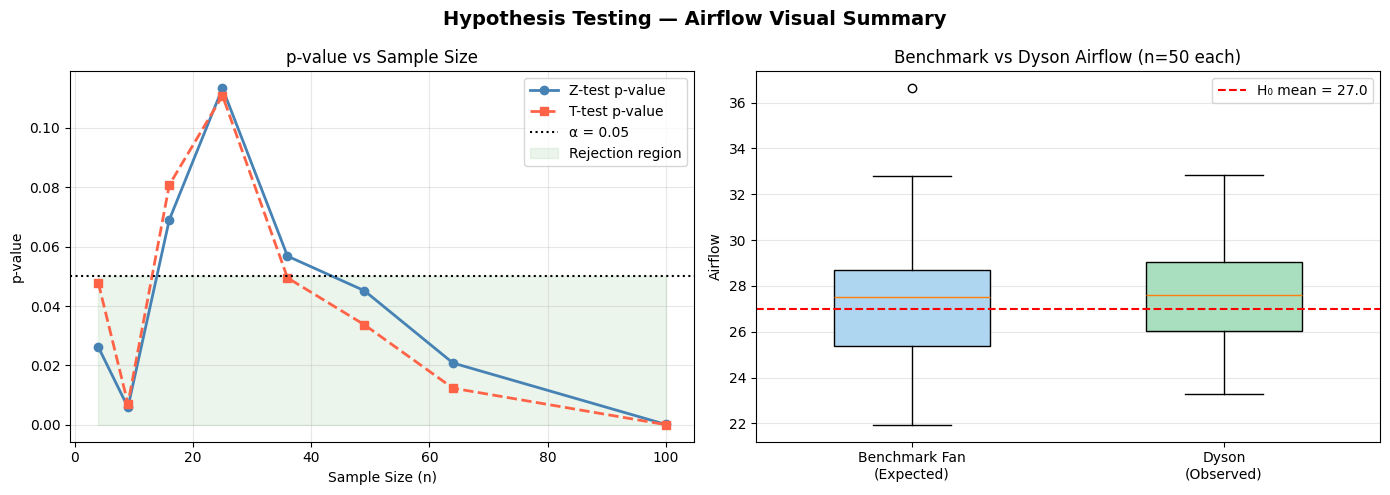

In [19]:
# ── 7. Visual: Z vs T statistics comparison (airflow) ──────────────────────────
import os

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: p-value vs sample size
ax = axes[0]
z_pvals = []
t_pvals = []
for n in sample_sizes:
    s = df_full['airflow'].iloc[:n].values
    se = SIGMA / np.sqrt(n)
    z = (s.mean() - POPULATION_MEAN_H0) / se
    z_pvals.append(2 * (1 - stats.norm.cdf(abs(z))))
    _, p = stats.ttest_1samp(s, POPULATION_MEAN_H0)
    t_pvals.append(p)

ax.plot(sample_sizes, z_pvals, 'o-', color='steelblue', lw=2, label='Z-test p-value')
ax.plot(sample_sizes, t_pvals, 's--', color='tomato', lw=2, label='T-test p-value')
ax.axhline(0.05, color='black', ls=':', lw=1.5, label='α = 0.05')
ax.fill_between(sample_sizes, 0, 0.05, alpha=0.08, color='green', label='Rejection region')
ax.set_xlabel('Sample Size (n)')
ax.set_ylabel('p-value')
ax.set_title('p-value vs Sample Size')
ax.legend()
ax.grid(alpha=0.3)

# Right: Box plots benchmark vs Dyson airflow
ax2 = axes[1]
bp = ax2.boxplot(
    [benchmark_airflow, dyson_airflow],
    labels=['Benchmark Fan\n(Expected)', 'Dyson\n(Observed)'],
    patch_artist=True,
    widths=0.5
)
bp['boxes'][0].set_facecolor('#AED6F1')
bp['boxes'][1].set_facecolor('#A9DFBF')
ax2.axhline(POPULATION_MEAN_H0, color='red', ls='--', lw=1.5, label=f'H₀ mean = {POPULATION_MEAN_H0}')
ax2.set_title('Benchmark vs Dyson Airflow (n=50 each)')
ax2.set_ylabel('Airflow')
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

plt.suptitle('Hypothesis Testing — Airflow Visual Summary', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(os.getcwd(), 'dyson_hypothesis_visuals.png'), dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# ── 8. Export datasets/results to CSV ──────────────────────────────────────────
import os

output_dir = os.getcwd()
df_full.to_csv(os.path.join(output_dir, 'Dyson.csv'), index=False)
df_z[DISPLAY_COLS].to_csv(os.path.join(output_dir, 'dyson_z_test_results.csv'), index=False)
df_t_results.to_csv(os.path.join(output_dir, 'dyson_t_test_results.csv'), index=False)

print(f'All files saved to: {output_dir}')
print('  • Dyson.csv')
print('  • dyson_z_test_results.csv')
print('  • dyson_t_test_results.csv')
print('  • dyson_hypothesis_table.png')
print('  • dyson_hypothesis_visuals.png')

All files saved to: c:\Users\siddi\OneDrive\Desktop\College\TE\SEM 6\Labs\DS Lab
  • Dyson.csv
  • dyson_z_test_results.csv
  • dyson_t_test_results.csv
  • dyson_hypothesis_table.png
  • dyson_hypothesis_visuals.png
